# 01 - What data do we have?

**Goal of the project:** the paper (Ye et al. 2026, *Nature Microbiology*) showed that
influenza A lineages which became established in mammals had lower GC content and fewer
GC-related dinucleotides than those that did not. We are testing whether similar genome
composition features show any pattern in RSV.

This notebook just looks at the dataset: how many sequences, from when, from where, and
what the quality filter removes.

In [1]:
import sys, os, subprocess
sys.path.insert(0, os.path.abspath("../src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = os.path.abspath("..")          # repo root; R scripts expect to run from here
pd.set_option("display.width", 120)

def run_r(script):
    """Run one of the R figure scripts from the repo root and report what it wrote."""
    r = subprocess.run(["Rscript", script], capture_output=True, text=True, cwd=ROOT)
    print(r.stdout.strip() or r.stderr.strip()[-400:])

def show(fig):
    """Display a figure from results/figures/ inline."""
    display(Image(os.path.join(ROOT, "results", "figures", fig)))


## The sequences

`rsv_features.tsv` is produced by `scripts/build_features.py`. One row per genome, with
the GISAID metadata plus the composition features already computed.

In [2]:
d = pd.read_csv("../data/processed/rsv_features.tsv", sep="\t")
print("sequences:", len(d))
print("subtypes:", d.Subtype.value_counts().to_dict())
print("years:", d.year.min(), "to", d.year.max())
# accession IDs are dropped from displays so no GISAID record is stored in the notebook
d.drop(columns=["Accession ID"]).head(3)

sequences: 33038
subtypes: {'B': 17580, 'A': 15458}
years: 2001 to 2026


,Subtype,Lineage,Genotype,date,year,region,country,seq_len_actual,ambig_frac,gc_content,valid_len,freq_CG,freq_GC,freq_GG,freq_CC,oe_CG,oe_GC,oe_GG,oe_CC
0,A,A.D.4.1,ON1,2022-01-25,2022,Africa,South Africa,15167,0.0,0.334278,15167,0.007055,0.028023,0.027562,0.033034,0.253442,1.006664,1.114623,1.054089
1,A,A.D.3,ON1,2022-02-02,2022,Africa,South Africa,15201,0.0,0.332873,15201,0.006711,0.027303,0.027434,0.033289,0.243172,0.989378,1.124800,1.066201
2,A,A.D.3,ON1,2022-02-03,2022,Africa,South Africa,15205,0.0,0.332917,15205,0.006709,0.027230,0.027361,0.033675,0.243079,0.986616,1.124292,1.075921


## How the QC filter was chosen

RSV genomes are about 15,200 nt. We keep sequences between **14,900 and 15,400 nt** and
with at most **1% ambiguous bases** (N or gaps), because ambiguous letters would distort
the dinucleotide counts. The histogram below shows why that window is sensible: almost
everything sits in a tight peak.

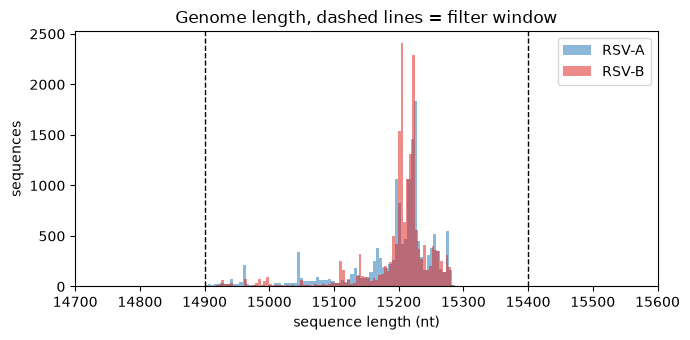

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for s, c in zip("AB", ["#2c7fb8", "#de2d26"]):
    ax.hist(d.loc[d.Subtype == s, "seq_len_actual"], bins=100, alpha=.55, label=f"RSV-{s}", color=c)
ax.axvline(14900, ls="--", c="k", lw=1); ax.axvline(15400, ls="--", c="k", lw=1)
ax.set_xlim(14700, 15600); ax.set_xlabel("sequence length (nt)"); ax.set_ylabel("sequences")
ax.legend(); ax.set_title("Genome length, dashed lines = filter window")
plt.tight_layout(); plt.show()

## When and where the sequences come from

Two things to notice, because they affect every trend later:

1. Sequencing ramps up sharply after 2018, and dips in 2020-21 (COVID-19 disrupted RSV
   circulation and surveillance).
2. Europe contributes far more sequences than anywhere else. Any trend over time is
   partly a trend in *who was sequencing*, not only in the virus.

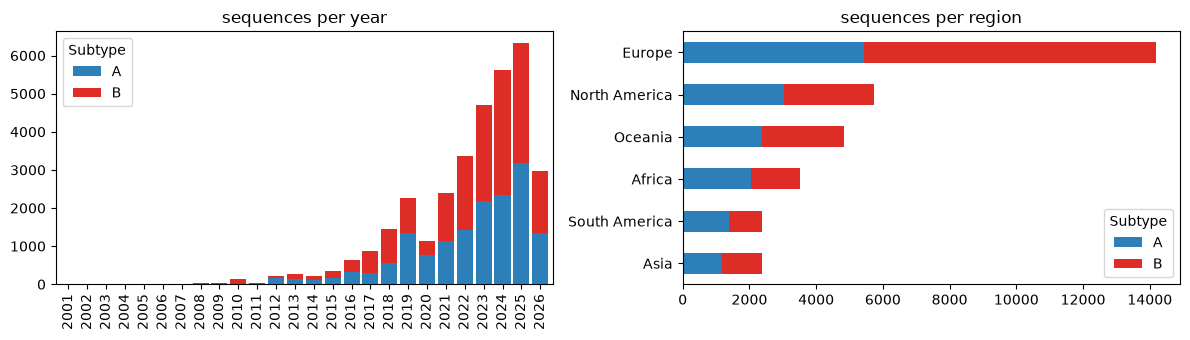

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
yr = d.groupby(["year", "Subtype"]).size().unstack(fill_value=0)
yr.plot.bar(stacked=True, ax=ax[0], color=["#2c7fb8", "#de2d26"], width=.85)
ax[0].set_title("sequences per year"); ax[0].set_xlabel("")
reg = d.groupby(["region", "Subtype"]).size().unstack(fill_value=0).sort_values("A")
reg.plot.barh(stacked=True, ax=ax[1], color=["#2c7fb8", "#de2d26"])
ax[1].set_title("sequences per region"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

## Lineages

GISAID assigns each genome to a **lineage** - a named branch of the RSV family tree.
Lineages rise and fall over time, which becomes important in notebook 04.

In [5]:
for s in "AB":
    top = d[d.Subtype == s].Lineage.value_counts().head(5)
    print(f"RSV-{s} most common lineages:")
    print(top.to_string(), "\n")

RSV-A most common lineages:
Lineage
A.D.3      2451
A.D.5.2    1523
A.D        1377
A.D.1      1196
A.D.1.5     998 

RSV-B most common lineages:
Lineage
B.D.E.1      9219
B.D.4.1.1    3237
B.D.E.1.2    1344
B.D.4.1       912
B.D.E.4       717 

